<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

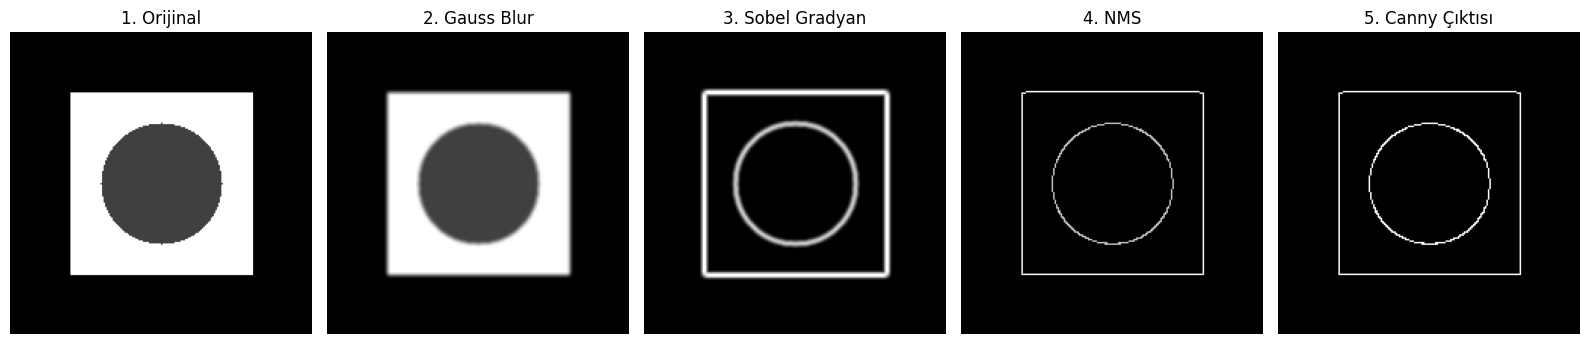

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 0. Test Görüntüsünü Otomatik Üret (Dosya yükleme derdi yok)
# -------------------------------------------------------------
img = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(img, (40, 40), (160, 160), 200, -1)
cv2.circle(img, (100, 100), 40, 50, -1)

# -------------------------------------------------------------
# 1. ADIM: Gürültü Bastırma (5x5 Gauss Filtresi)
# -------------------------------------------------------------
def gaussian_blur(image):
    kernel = np.array([
        [2,  4,  5,  4, 2],
        [4,  9, 12,  9, 4],
        [5, 12, 15, 12, 5],
        [4,  9, 12,  9, 4],
        [2,  4,  5,  4, 2]
    ], dtype=np.float32) / 159.0

    pad = 2
    h, w = image.shape
    padded = np.pad(image, pad, mode='reflect')
    blurred = np.zeros_like(image, dtype=np.float32)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+5, j:j+5]
            blurred[i, j] = np.sum(region * kernel)

    return blurred

# -------------------------------------------------------------
# 2. ADIM: Sobel Filtresi ile Gradyan Hesaplama
# -------------------------------------------------------------
def sobel_filters(image):
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
    Ky = np.array([[ 1,  2,  1], [ 0,  0,  0], [-1, -2, -1]], dtype=np.float32)

    pad = 1
    h, w = image.shape
    padded = np.pad(image, pad, mode='reflect')

    Ix = np.zeros_like(image, dtype=np.float32)
    Iy = np.zeros_like(image, dtype=np.float32)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+3, j:j+3]
            Ix[i, j] = np.sum(region * Kx)
            Iy[i, j] = np.sum(region * Ky)

    magnitude = np.hypot(Ix, Iy)
    if magnitude.max() > 0:
        magnitude = (magnitude / magnitude.max()) * 255.0
    theta = np.arctan2(Iy, Ix)

    return magnitude, theta

# -------------------------------------------------------------
# 3. ADIM: Non-Maximum Suppression (NMS)
# -------------------------------------------------------------
def non_maximum_suppression(magnitude, theta):
    h, w = magnitude.shape
    output = np.zeros((h, w), dtype=np.float32)

    angle = theta * 180.0 / np.pi
    angle[angle < 0] += 180

    for i in range(1, h - 1):
        for j in range(1, w - 1):
            q, r = 255.0, 255.0

            if (0 <= angle[i, j] < 22.5) or (157.5 <= angle[i, j] <= 180):
                q = magnitude[i, j + 1]
                r = magnitude[i, j - 1]
            elif 22.5 <= angle[i, j] < 67.5:
                q = magnitude[i + 1, j - 1]
                r = magnitude[i - 1, j + 1]
            elif 67.5 <= angle[i, j] < 112.5:
                q = magnitude[i + 1, j]
                r = magnitude[i - 1, j]
            elif 112.5 <= angle[i, j] < 157.5:
                q = magnitude[i - 1, j - 1]
                r = magnitude[i + 1, j + 1]

            if (magnitude[i, j] >= q) and (magnitude[i, j] >= r):
                output[i, j] = magnitude[i, j]
            else:
                output[i, j] = 0

    return output

# -------------------------------------------------------------
# 4. ADIM: Hysteresis Thresholding
# -------------------------------------------------------------
def hysteresis_thresholding(image, low_ratio=0.1, high_ratio=0.3):
    high_thresh = image.max() * high_ratio
    low_thresh = high_thresh * low_ratio

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.uint8)

    strong_val = 255
    weak_val = 75

    strong_i, strong_j = np.where(image >= high_thresh)
    weak_i, weak_j = np.where((image >= low_thresh) & (image < high_thresh))

    output[strong_i, strong_j] = strong_val
    output[weak_i, weak_j] = weak_val

    for i in range(1, h - 1):
        for j in range(1, w - 1):
            if output[i, j] == weak_val:
                if np.any(output[i-1:i+2, j-1:j+2] == strong_val):
                    output[i, j] = strong_val
                else:
                    output[i, j] = 0

    return output

# -------------------------------------------------------------
# ÇALIŞTIRMA VE GÖRSELLEŞTİRME
# -------------------------------------------------------------
blurred = gaussian_blur(img)
magnitude, theta = sobel_filters(blurred)
nms = non_maximum_suppression(magnitude, theta)
edges = hysteresis_thresholding(nms)

titles = ["1. Orijinal", "2. Gauss Blur", "3. Sobel Gradyan", "4. NMS", "5. Canny Çıktısı"]
images = [img, blurred, magnitude, nms, edges]

plt.figure(figsize=(16, 4))
for idx, (title, im) in enumerate(zip(titles, images)):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(im, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()